# Tugas 1 - Prediksi Customer Churn dengan Artificial Neural Network (PyTorch)

| Nama | NRP |
|------|-----|
| Muhamad Nafi Mulyo | 5054251005 |

## Deskripsi Tugas
Pada tugas ini, kita akan menggunakan Churn Modelling Dataset. Dataset bisa diakses melalui link berikut:\
https://www.kaggle.com/datasets/shrutimechlearn/churn-modelling

Dataset berisi data 10.000 nasabah bank, seperti skor kredit, negara, usia, saldo, dan status keaktifan. Tujuan utama dari tugas ini adalah membangun model Artificial Neural Network (ANN) menggunakan **PyTorch** untuk memprediksi apakah seorang nasabah akan berhenti menjadi nasabah (churn, kolom `Exited`) atau tidak.

Langkah-langkah yang harus dilakukan antara lain:
1. Persiapan Dataset dan Eksplorasi Awal
   - Memuat dataset, melihat struktur data, dan distribusi label.
2. Preprocessing
   - Memproses data agar siap digunakan oleh ANN.
3. Eksperimen Model
   - Bangun model baseline Logistic Regression dan beberapa konfigurasi ANN.
4. Evaluasi Model
   - Hitung metrik evaluasi dan visualisasikan hasilnya.
5. Analisis dan Kesimpulan
   - Bandingkan hasil seluruh model dan berikan kesimpulan.

# 1. Persiapan Dataset dan Eksplorasi Awal

In [1]:
# Import library yang dibutuhkan (pandas, numpy, matplotlib, seaborn, sklearn, torch, dll).
# Dari torch, import juga torch.nn dan TensorDataset, DataLoader dari torch.utils.data.
# Set random seed agar hasil eksperimen dapat direproduksi, gunakan torch.manual_seed(42) dan np.random.seed(42).

import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix, roc_curve, roc_auc_score)

import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader

SEED = 42
torch.manual_seed(SEED)
np.random.seed(SEED)
sns.set_theme(style="whitegrid")
print("PyTorch", torch.__version__)


PyTorch 2.15.0+cu132


In [2]:
# Load dataset dan tampilkan beberapa baris pertama.
# Tampilkan informasi dasar: jumlah baris dan kolom, tipe data, statistik deskriptif, dan jumlah missing value.

df = pd.read_csv("data/Churn_Modelling.csv")
display(df.head())
print("Shape:", df.shape)
df.info()
display(df.describe())
print("Missing value per kolom:")
print(df.isnull().sum())


,RowNumber,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,1,15634602,Hargrave,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,2,15647311,Hill,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,3,15619304,Onio,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
3,4,15701354,Boni,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,5,15737888,Mitchell,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0


Shape: (10000, 14)
<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   RowNumber        10000 non-null  int64  
 1   CustomerId       10000 non-null  int64  
 2   Surname          10000 non-null  str    
 3   CreditScore      10000 non-null  int64  
 4   Geography        10000 non-null  str    
 5   Gender           10000 non-null  str    
 6   Age              10000 non-null  int64  
 7   Tenure           10000 non-null  int64  
 8   Balance          10000 non-null  float64
 9   NumOfProducts    10000 non-null  int64  
 10  HasCrCard        10000 non-null  int64  
 11  IsActiveMember   10000 non-null  int64  
 12  EstimatedSalary  10000 non-null  float64
 13  Exited           10000 non-null  int64  
dtypes: float64(2), int64(9), str(3)
memory usage: 1.1 MB


,RowNumber,CustomerId,CreditScore,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
count,10000.00000,1.000000e+04,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.00000,10000.000000,10000.000000,10000.000000
mean,5000.50000,1.569094e+07,650.528800,38.921800,5.012800,76485.889288,1.530200,0.70550,0.515100,100090.239881,0.203700
std,2886.89568,7.193619e+04,96.653299,10.487806,2.892174,62397.405202,0.581654,0.45584,0.499797,57510.492818,0.402769
min,1.00000,1.556570e+07,350.000000,18.000000,0.000000,0.000000,1.000000,0.00000,0.000000,11.580000,0.000000
25%,2500.75000,1.562853e+07,584.000000,32.000000,3.000000,0.000000,1.000000,0.00000,0.000000,51002.110000,0.000000
50%,5000.50000,1.569074e+07,652.000000,37.000000,5.000000,97198.540000,1.000000,1.00000,1.000000,100193.915000,0.000000
75%,7500.25000,1.575323e+07,718.000000,44.000000,7.000000,127644.240000,2.000000,1.00000,1.000000,149388.247500,0.000000
max,10000.00000,1.581569e+07,850.000000,92.000000,10.000000,250898.090000,4.000000,1.00000,1.000000,199992.480000,1.000000


Missing value per kolom:
RowNumber          0
CustomerId         0
Surname            0
CreditScore        0
Geography          0
Gender             0
Age                0
Tenure             0
Balance            0
NumOfProducts      0
HasCrCard          0
IsActiveMember     0
EstimatedSalary    0
Exited             0
dtype: int64


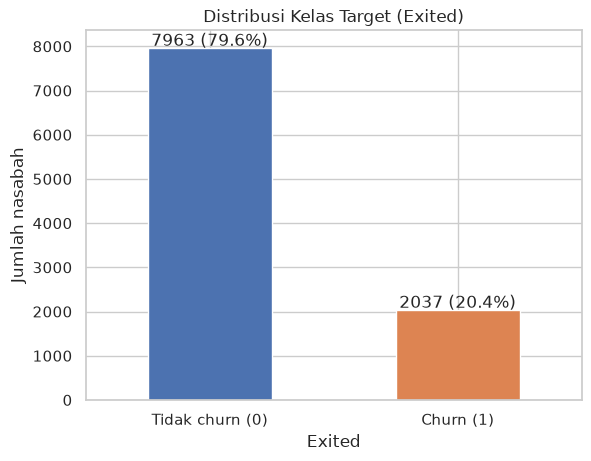

In [3]:
# Tampilkan distribusi kelas target (Exited) dalam bentuk bar plot.
# Perhatikan apakah dataset ini imbalanced.

counts = df["Exited"].value_counts().sort_index()
ax = counts.plot(kind="bar", color=["#4C72B0", "#DD8452"])
ax.set_xticklabels(["Tidak churn (0)", "Churn (1)"], rotation=0)
ax.set_title("Distribusi Kelas Target (Exited)")
ax.set_ylabel("Jumlah nasabah")
for i, v in enumerate(counts):
    ax.text(i, v + 50, f"{v} ({v / len(df):.1%})", ha="center")
plt.show()


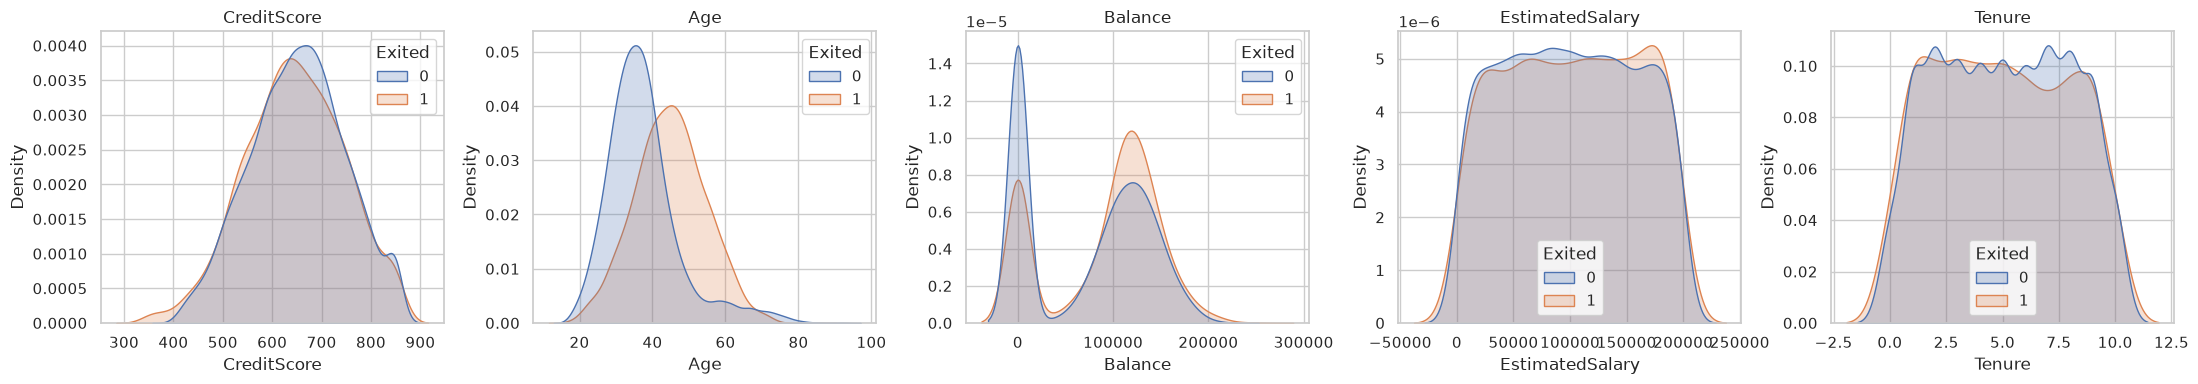

In [4]:
# Tampilkan distribusi fitur numerik (misalnya Age, CreditScore, Balance) menggunakan histogram atau KDE plot, dibedakan berdasarkan kelas Exited.

num_cols = ["CreditScore", "Age", "Balance", "EstimatedSalary", "Tenure"]
fig, axes = plt.subplots(1, len(num_cols), figsize=(22, 4))
for ax, col in zip(axes, num_cols):
    sns.kdeplot(data=df, x=col, hue="Exited", common_norm=False, fill=True, ax=ax)
    ax.set_title(col)
plt.tight_layout()
plt.show()


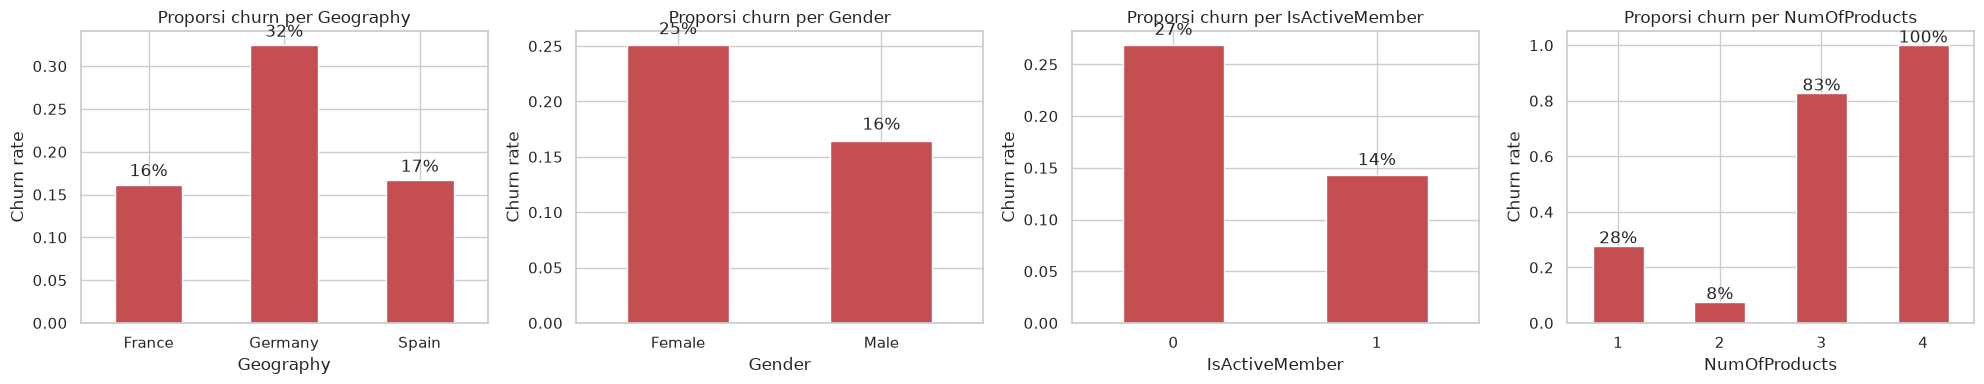

In [5]:
# Tampilkan proporsi churn untuk setiap kategori pada fitur kategorikal (Geography, Gender, IsActiveMember, NumOfProducts).

cat_cols = ["Geography", "Gender", "IsActiveMember", "NumOfProducts"]
fig, axes = plt.subplots(1, len(cat_cols), figsize=(20, 4))
for ax, col in zip(axes, cat_cols):
    rate = df.groupby(col)["Exited"].mean()
    rate.plot(kind="bar", ax=ax, color="#C44E52")
    ax.set_title(f"Proporsi churn per {col}")
    ax.set_ylabel("Churn rate")
    ax.tick_params(axis="x", rotation=0)
    for i, v in enumerate(rate):
        ax.text(i, v + 0.01, f"{v:.0%}", ha="center")
plt.tight_layout()
plt.show()


## Lakukan Exploratory Data Analysis (EDA) tambahan yang diperlukan.

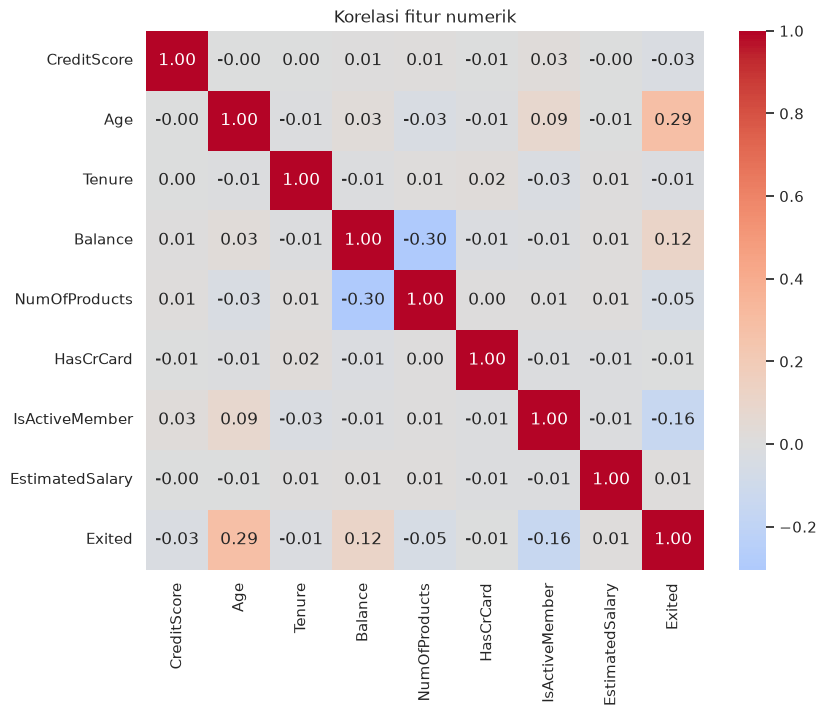

,count,churn_rate
Age,,
18-30,1968,0.075203
31-40,4451,0.120872
41-50,2320,0.339655
51-60,797,0.562108
60+,464,0.247845


Proporsi nasabah dengan Balance = 0: 0.362


Balance
False    0.240796
True     0.138236
Name: churn_rate, dtype: float64

In [6]:
# EDA tambahan: korelasi antar fitur numerik dan churn rate per kelompok usia
corr_cols = ["CreditScore", "Age", "Tenure", "Balance", "NumOfProducts",
             "HasCrCard", "IsActiveMember", "EstimatedSalary", "Exited"]
plt.figure(figsize=(9, 7))
sns.heatmap(df[corr_cols].corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Korelasi fitur numerik")
plt.show()

age_bins = pd.cut(df["Age"], bins=[17, 30, 40, 50, 60, 100], labels=["18-30", "31-40", "41-50", "51-60", "60+"])
display(df.groupby(age_bins, observed=True)["Exited"].agg(["count", "mean"]).rename(columns={"mean": "churn_rate"}))
print("Proporsi nasabah dengan Balance = 0:", (df["Balance"] == 0).mean().round(3))
display(df.groupby(df["Balance"] == 0)["Exited"].mean().rename("churn_rate"))


# 2. Preprocessing

ANN hanya menerima input numerik dan sangat sensitif terhadap skala fitur. Perhatikan jenis setiap kolom sebelum memilih preprocessing:

| Jenis kolom | Contoh | Preprocessing |
|---|---|---|
| Identitas (tidak informatif) | RowNumber, CustomerId, Surname | Drop |
| Kategorikal nominal | Geography | OneHotEncoder |
| Kategorikal biner | Gender | Encode menjadi 0/1 |
| Numerik | CreditScore, Age, Balance, dll. | StandardScaler |

In [7]:
# Drop kolom yang tidak relevan untuk prediksi.
# Jelaskan secara singkat (dalam komentar) alasan kolom tersebut di-drop.

# RowNumber hanya nomor urut, CustomerId adalah ID unik, dan Surname adalah nama keluarga.
# Ketiganya tidak membawa informasi tentang perilaku nasabah, sehingga hanya akan menambah noise
# (atau membuat model menghafal identitas), jadi di-drop.
df_model = df.drop(columns=["RowNumber", "CustomerId", "Surname"])
df_model.head()


,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
3,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0


In [8]:
# Pisahkan fitur (X) dan target (y).
# Bagi data menjadi train set, validation set, dan test set (misalnya 70:15:15).
# Gunakan stratify=y agar distribusi kelas tetap proporsional di setiap set.
# Validation set digunakan untuk memantau training (learning curve), test set hanya digunakan untuk evaluasi akhir.

X = df_model.drop(columns=["Exited"])
y = df_model["Exited"].values

X_train, X_temp, y_train, y_temp = train_test_split(X, y, test_size=0.30, stratify=y, random_state=SEED)
X_val, X_test, y_val, y_test = train_test_split(X_temp, y_temp, test_size=0.50, stratify=y_temp, random_state=SEED)

for name, yy in [("Train", y_train), ("Val", y_val), ("Test", y_test)]:
    print(f"{name:5s}: {len(yy):5d} baris, churn rate = {yy.mean():.3f}")


Train:  7000 baris, churn rate = 0.204
Val  :  1500 baris, churn rate = 0.204
Test :  1500 baris, churn rate = 0.203


In [9]:
# Lakukan encoding pada fitur kategorikal dan scaling pada fitur numerik.
# Fit encoder dan scaler hanya pada train set, kemudian transform pada train, validation, dan test set.
# Disarankan menggunakan ColumnTransformer agar rapi.

# Gender adalah biner; OneHotEncoder(drop="if_binary") mengubahnya menjadi satu kolom 0/1.
num_features = ["CreditScore", "Age", "Tenure", "Balance", "NumOfProducts", "EstimatedSalary"]
bin_features = ["HasCrCard", "IsActiveMember"]  # sudah 0/1, dibiarkan apa adanya

preprocessor = ColumnTransformer([
    ("geo", OneHotEncoder(handle_unknown="ignore"), ["Geography"]),
    ("gender", OneHotEncoder(drop="if_binary"), ["Gender"]),
    ("num", StandardScaler(), num_features),
    ("bin", "passthrough", bin_features),
])

X_train_p = preprocessor.fit_transform(X_train)
X_val_p = preprocessor.transform(X_val)
X_test_p = preprocessor.transform(X_test)
feature_names = preprocessor.get_feature_names_out()
print("Jumlah fitur setelah preprocessing:", X_train_p.shape[1])
print(list(feature_names))


Jumlah fitur setelah preprocessing: 12
['geo__Geography_France', 'geo__Geography_Germany', 'geo__Geography_Spain', 'gender__Gender_Male', 'num__CreditScore', 'num__Age', 'num__Tenure', 'num__Balance', 'num__NumOfProducts', 'num__EstimatedSalary', 'bin__HasCrCard', 'bin__IsActiveMember']


In [10]:
# Ubah X dan y untuk train, validation, dan test menjadi tensor bertipe float32.
# Bentuk y diubah menjadi (N, 1) agar sesuai dengan output model, contoh: torch.tensor(y, dtype=torch.float32).view(-1, 1)
# Buat DataLoader untuk train set (shuffle=True) menggunakan TensorDataset.

def to_tensor(X, y):
    return (torch.tensor(X, dtype=torch.float32),
            torch.tensor(y, dtype=torch.float32).view(-1, 1))

Xtr_t, ytr_t = to_tensor(X_train_p, y_train)
Xva_t, yva_t = to_tensor(X_val_p, y_val)
Xte_t, yte_t = to_tensor(X_test_p, y_test)

BATCH_SIZE = 64
g = torch.Generator().manual_seed(SEED)
train_loader = DataLoader(TensorDataset(Xtr_t, ytr_t), batch_size=BATCH_SIZE, shuffle=True, generator=g)
print(Xtr_t.shape, ytr_t.shape, Xva_t.shape, Xte_t.shape)


torch.Size([7000, 12]) torch.Size([7000, 1]) torch.Size([1500, 12]) torch.Size([1500, 12])


# 3. Eksperimen Model

## 3.1 Baseline: Logistic Regression

Sebelum membangun ANN, buat model sederhana sebagai pembanding. Model yang lebih kompleks hanya layak digunakan jika performanya lebih baik dari baseline.

In [11]:
# Inisialisasi dan latih model Logistic Regression (sklearn) menggunakan train set.
# Lakukan prediksi pada test set, simpan hasil prediksi label dan probabilitas kelas 1.

logreg = LogisticRegression(max_iter=1000, random_state=SEED)
logreg.fit(X_train_p, y_train)

results = {}  # nama model -> (y_pred, y_prob)
lr_prob = logreg.predict_proba(X_test_p)[:, 1]
lr_pred = (lr_prob >= 0.5).astype(int)
results["Logistic Regression"] = (lr_pred, lr_prob)
print("Test accuracy Logistic Regression:", accuracy_score(y_test, lr_pred))


Test accuracy Logistic Regression: 0.8153333333333334


## 3.2 ANN Sederhana

Bangun ANN dengan **1 hidden layer** dan **1 neuron output**. Di PyTorch, output layer cukup berupa `nn.Linear` tanpa Sigmoid, lalu gunakan **`nn.BCEWithLogitsLoss`** sebagai loss function. Loss ini sudah menggabungkan Sigmoid dan Binary Cross-Entropy sehingga lebih stabil secara numerik.

Contoh arsitektur: `Input → Linear(16) → ReLU → Linear(1)`

In [12]:
# Definisikan arsitektur ANN sederhana sebagai class turunan nn.Module (gunakan nn.Sequential, nn.Linear, dan nn.ReLU).
# Tampilkan arsitektur model dengan print(model) dan hitung jumlah parameternya: sum(p.numel() for p in model.parameters()).

N_FEATURES = Xtr_t.shape[1]

class SimpleANN(nn.Module):
    def __init__(self, n_in, hidden=16):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(n_in, hidden),
            nn.ReLU(),
            nn.Linear(hidden, 1),  # output logit, tanpa Sigmoid
        )

    def forward(self, x):
        return self.net(x)

def count_params(model):
    return sum(p.numel() for p in model.parameters())

torch.manual_seed(SEED)
model_simple = SimpleANN(N_FEATURES)
print(model_simple)
print("Jumlah parameter:", count_params(model_simple))


SimpleANN(
  (net): Sequential(
    (0): Linear(in_features=12, out_features=16, bias=True)
    (1): ReLU()
    (2): Linear(in_features=16, out_features=1, bias=True)
  )
)
Jumlah parameter: 225


In [13]:
# Tentukan loss function (nn.BCEWithLogitsLoss), optimizer (misalnya torch.optim.Adam), learning rate, jumlah epoch, dan batch size.
# Tulis training loop. Untuk setiap batch: forward -> hitung loss -> optimizer.zero_grad() -> loss.backward() -> optimizer.step().
# Di akhir setiap epoch, hitung loss dan accuracy pada train set dan validation set (gunakan model.eval() dan torch.no_grad()),
# lalu simpan ke dictionary history.
# Disarankan membuat training loop dalam bentuk fungsi agar dapat digunakan ulang pada 3.3 dan 3.4.

EPOCHS = 100
LR = 1e-3

@torch.no_grad()
def evaluate(model, X, y, criterion):
    model.eval()
    logits = model(X)
    loss = criterion(logits, y).item()
    acc = ((torch.sigmoid(logits) >= 0.5).float() == y).float().mean().item()
    return loss, acc

def train_model(model, criterion, epochs=EPOCHS, lr=LR, verbose_every=20):
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    history = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": []}
    for epoch in range(1, epochs + 1):
        model.train()
        for xb, yb in train_loader:
            loss = criterion(model(xb), yb)
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()
        tr_loss, tr_acc = evaluate(model, Xtr_t, ytr_t, criterion)
        va_loss, va_acc = evaluate(model, Xva_t, yva_t, criterion)
        history["train_loss"].append(tr_loss); history["val_loss"].append(va_loss)
        history["train_acc"].append(tr_acc); history["val_acc"].append(va_acc)
        if epoch % verbose_every == 0 or epoch == 1:
            print(f"Epoch {epoch:3d} | loss {tr_loss:.4f} / val {va_loss:.4f} | acc {tr_acc:.4f} / val {va_acc:.4f}")
    return history

criterion = nn.BCEWithLogitsLoss()
hist_simple = train_model(model_simple, criterion)


Epoch   1 | loss 0.4881 / val 0.4871 | acc 0.7963 / val 0.7960


Epoch  20 | loss 0.3474 / val 0.3320 | acc 0.8554 / val 0.8627


Epoch  40 | loss 0.3407 / val 0.3277 | acc 0.8587 / val 0.8620


Epoch  60 | loss 0.3376 / val 0.3269 | acc 0.8596 / val 0.8633


Epoch  80 | loss 0.3357 / val 0.3270 | acc 0.8619 / val 0.8633


Epoch 100 | loss 0.3339 / val 0.3254 | acc 0.8633 / val 0.8620


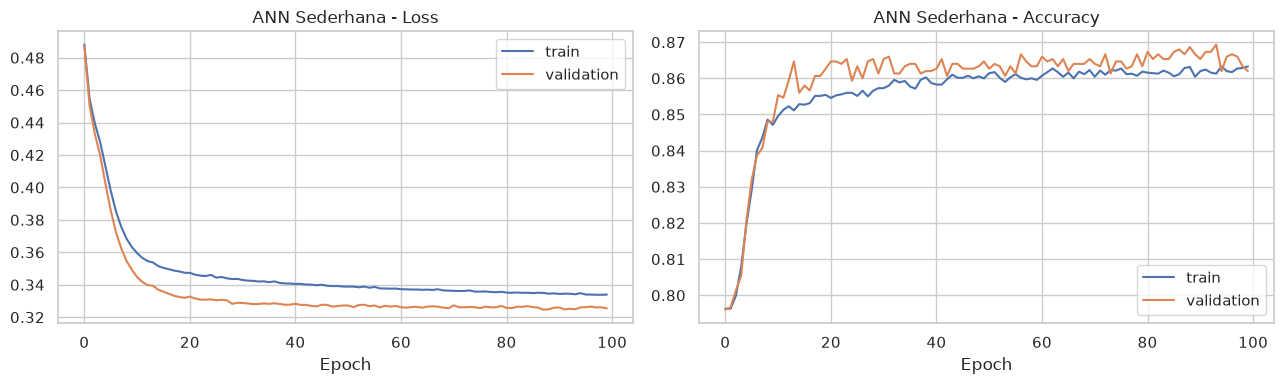

In [14]:
# Tampilkan learning curve (loss dan accuracy) train vs validation dalam bentuk line plot menggunakan dictionary history.

def plot_history(history, title):
    fig, axes = plt.subplots(1, 2, figsize=(13, 4))
    for ax, metric in zip(axes, ["loss", "acc"]):
        ax.plot(history[f"train_{metric}"], label="train")
        ax.plot(history[f"val_{metric}"], label="validation")
        ax.set_title(f"{title} - {'Loss' if metric == 'loss' else 'Accuracy'}")
        ax.set_xlabel("Epoch")
        ax.legend()
    plt.tight_layout()
    plt.show()

plot_history(hist_simple, "ANN Sederhana")


In [15]:
# Lakukan prediksi pada test set. Gunakan model.eval() dan torch.no_grad().
# Output model berupa logit, ubah menjadi probabilitas dengan torch.sigmoid(), lalu menjadi label dengan threshold 0.5.
# Simpan probabilitas dan label dalam bentuk numpy array untuk keperluan evaluasi.

@torch.no_grad()
def predict(model, X, threshold=0.5):
    model.eval()
    prob = torch.sigmoid(model(X)).numpy().ravel()
    return (prob >= threshold).astype(int), prob

results["ANN Sederhana"] = predict(model_simple, Xte_t)
print("Test accuracy ANN Sederhana:", accuracy_score(y_test, results["ANN Sederhana"][0]))


Test accuracy ANN Sederhana: 0.8666666666666667


## 3.3 ANN Lebih Dalam dengan Dropout

Bangun ANN dengan **2–3 hidden layer** dan tambahkan **Dropout** di antara hidden layer untuk mengurangi overfitting.

In [16]:
# Definisikan arsitektur ANN yang lebih dalam, tambahkan nn.Dropout(p) di antara hidden layer.
# Ingat: Dropout hanya aktif saat model.train() dan otomatis nonaktif saat model.eval().
# Tampilkan arsitektur model beserta jumlah parameternya.

class DeepANN(nn.Module):
    def __init__(self, n_in, p=0.3):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(n_in, 64), nn.ReLU(), nn.Dropout(p),
            nn.Linear(64, 32), nn.ReLU(), nn.Dropout(p),
            nn.Linear(32, 16), nn.ReLU(),
            nn.Linear(16, 1),
        )

    def forward(self, x):
        return self.net(x)

torch.manual_seed(SEED)
model_deep = DeepANN(N_FEATURES)
print(model_deep)
print("Jumlah parameter:", count_params(model_deep))


DeepANN(
  (net): Sequential(
    (0): Linear(in_features=12, out_features=64, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.3, inplace=False)
    (3): Linear(in_features=64, out_features=32, bias=True)
    (4): ReLU()
    (5): Dropout(p=0.3, inplace=False)
    (6): Linear(in_features=32, out_features=16, bias=True)
    (7): ReLU()
    (8): Linear(in_features=16, out_features=1, bias=True)
  )
)
Jumlah parameter: 3457


Epoch   1 | loss 0.4534 / val 0.4466 | acc 0.7963 / val 0.7960


Epoch  20 | loss 0.3320 / val 0.3269 | acc 0.8631 / val 0.8640


Epoch  40 | loss 0.3219 / val 0.3231 | acc 0.8686 / val 0.8680


Epoch  60 | loss 0.3139 / val 0.3223 | acc 0.8746 / val 0.8673


Epoch  80 | loss 0.3075 / val 0.3278 | acc 0.8753 / val 0.8653


Epoch 100 | loss 0.3007 / val 0.3266 | acc 0.8794 / val 0.8633


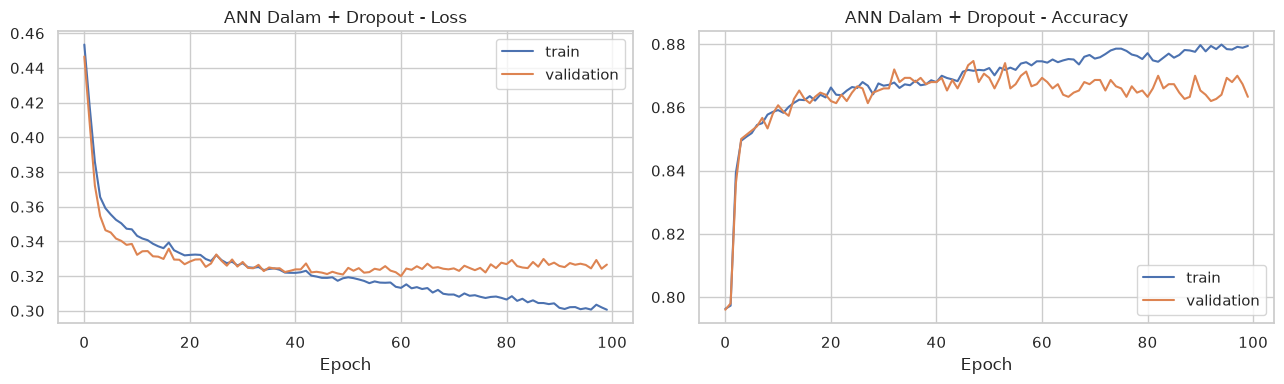

In [17]:
# Latih model dengan cara yang sama seperti 3.2, lalu tampilkan learning curve train vs validation.
# Bandingkan bentuk learning curve-nya dengan model 3.2. Apakah ada tanda overfitting?

hist_deep = train_model(model_deep, criterion)
plot_history(hist_deep, "ANN Dalam + Dropout")


In [18]:
# Lakukan prediksi pada test set.
# Simpan hasil prediksi label dan probabilitas kelas 1 untuk keperluan evaluasi.

results["ANN Dalam + Dropout"] = predict(model_deep, Xte_t)
print("Test accuracy ANN Dalam + Dropout:", accuracy_score(y_test, results["ANN Dalam + Dropout"][0]))


Test accuracy ANN Dalam + Dropout: 0.8753333333333333


## 3.4 Penanganan Data Imbalanced

Pada data imbalanced, model cenderung lebih sering memprediksi kelas mayoritas sehingga recall kelas churn rendah. Salah satu cara mengatasinya adalah dengan memberi bobot lebih besar pada kelas minoritas di loss function.

In [19]:
# Gunakan arsitektur terbaik dari 3.2 atau 3.3 (buat ulang modelnya agar bobot mulai dari awal), lalu latih dengan class weight.
# Hitung pos_weight = jumlah kelas 0 / jumlah kelas 1 pada train set.
# Masukkan ke loss function: nn.BCEWithLogitsLoss(pos_weight=torch.tensor([pos_weight])).

# Arsitektur yang dipakai: DeepANN (3.3). Pilihan ini dicek ulang di analisis berdasarkan hasil 3.2 vs 3.3.
pos_weight = (y_train == 0).sum() / (y_train == 1).sum()
print(f"pos_weight = {pos_weight:.3f}")

torch.manual_seed(SEED)
model_weighted = DeepANN(N_FEATURES)
criterion_weighted = nn.BCEWithLogitsLoss(pos_weight=torch.tensor([pos_weight], dtype=torch.float32))
hist_weighted = train_model(model_weighted, criterion_weighted)


pos_weight = 3.909
Epoch   1 | loss 0.9300 / val 0.9087 | acc 0.6793 / val 0.6793


Epoch  20 | loss 0.7163 / val 0.7055 | acc 0.8133 / val 0.8133


Epoch  40 | loss 0.6864 / val 0.6935 | acc 0.7927 / val 0.7840


Epoch  60 | loss 0.6687 / val 0.6964 | acc 0.8050 / val 0.8013


Epoch  80 | loss 0.6492 / val 0.7014 | acc 0.8141 / val 0.8013


Epoch 100 | loss 0.6364 / val 0.7060 | acc 0.8113 / val 0.7940


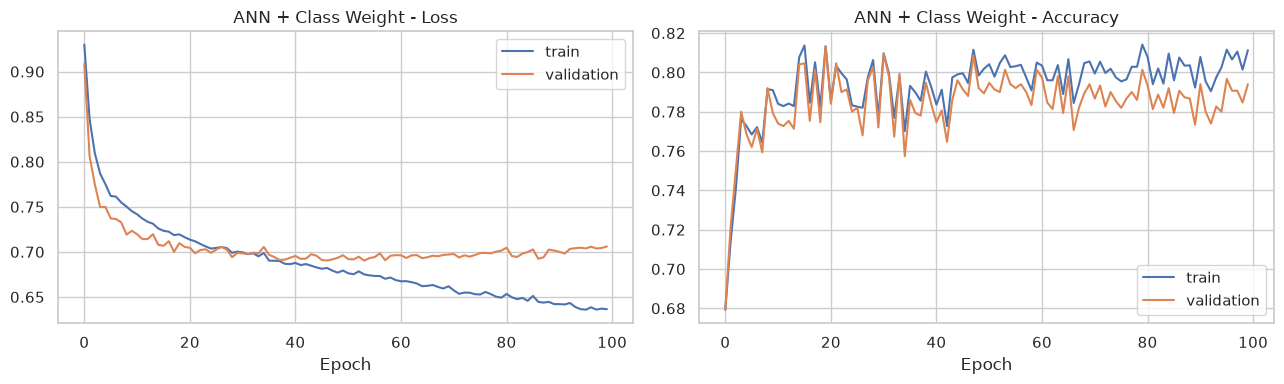

Test accuracy ANN + Class Weight: 0.7846666666666666


In [20]:
# Tampilkan learning curve train vs validation.
# Lakukan prediksi pada test set, simpan hasil prediksi label dan probabilitas kelas 1.

plot_history(hist_weighted, "ANN + Class Weight")
results["ANN + Class Weight"] = predict(model_weighted, Xte_t)
print("Test accuracy ANN + Class Weight:", accuracy_score(y_test, results["ANN + Class Weight"][0]))


# 4. Evaluasi Model

In [21]:
# Tampilkan metrik evaluasi untuk setiap model: Accuracy, Precision, Recall, dan F1-Score.
# Sajikan dalam satu tabel perbandingan agar mudah dibandingkan.

rows = []
for name, (pred, prob) in results.items():
    rows.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, pred),
        "Precision": precision_score(y_test, pred),
        "Recall": recall_score(y_test, pred),
        "F1-Score": f1_score(y_test, pred),
        "ROC-AUC": roc_auc_score(y_test, prob),
    })
metrics_df = pd.DataFrame(rows).set_index("Model").round(4)
metrics_df


,Accuracy,Precision,Recall,F1-Score,ROC-AUC
Model,,,,,
Logistic Regression,0.8153,0.6458,0.2033,0.3092,0.7913
ANN Sederhana,0.8667,0.7807,0.4787,0.5935,0.8665
ANN Dalam + Dropout,0.8753,0.8138,0.5016,0.6207,0.8674
ANN + Class Weight,0.7847,0.4815,0.7672,0.5917,0.8686


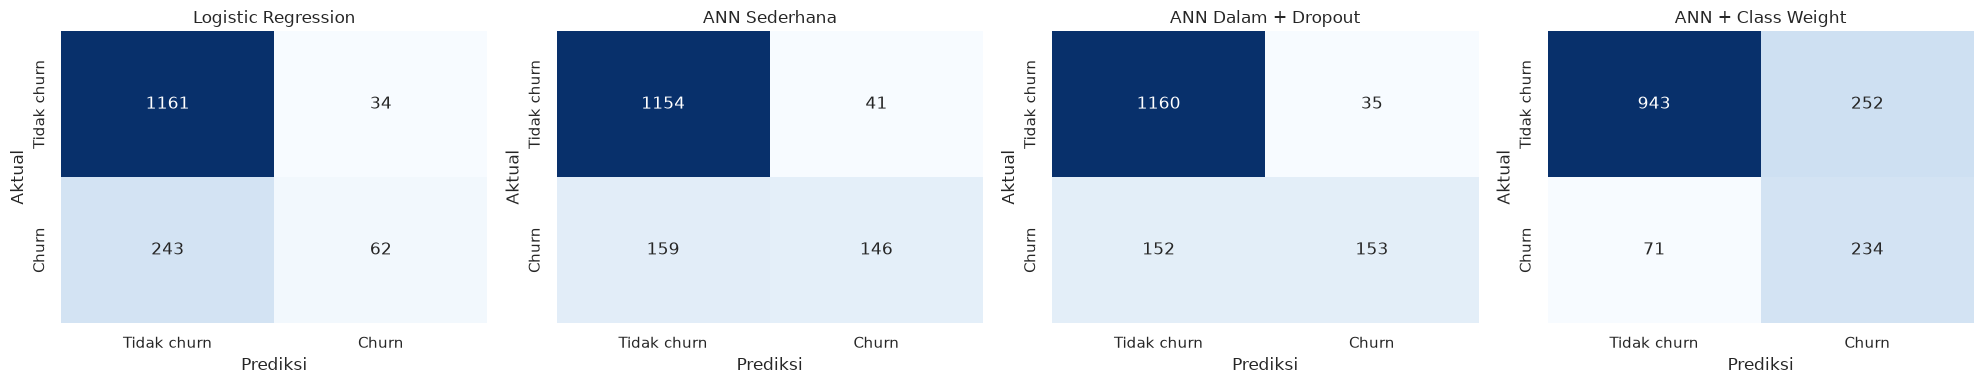

In [22]:
# Tampilkan Confusion Matrix setiap model dalam bentuk heatmap.
# Susun dalam satu baris subplot.

fig, axes = plt.subplots(1, len(results), figsize=(5 * len(results), 4))
for ax, (name, (pred, _)) in zip(axes, results.items()):
    cm = confusion_matrix(y_test, pred)
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax,
                xticklabels=["Tidak churn", "Churn"], yticklabels=["Tidak churn", "Churn"])
    ax.set_title(name)
    ax.set_xlabel("Prediksi")
    ax.set_ylabel("Aktual")
plt.tight_layout()
plt.show()


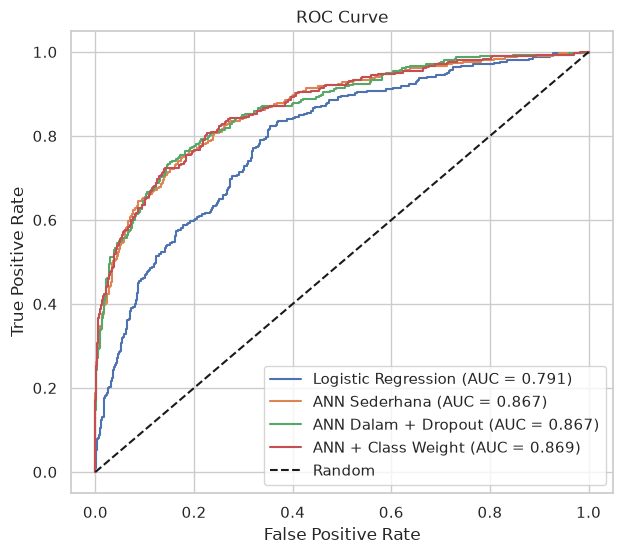

In [23]:
# Tampilkan ROC Curve seluruh model dalam satu plot beserta nilai AUC masing-masing.

plt.figure(figsize=(7, 6))
for name, (_, prob) in results.items():
    fpr, tpr, _ = roc_curve(y_test, prob)
    plt.plot(fpr, tpr, label=f"{name} (AUC = {roc_auc_score(y_test, prob):.3f})")
plt.plot([0, 1], [0, 1], "k--", label="Random")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve")
plt.legend()
plt.show()


# 5. Analisis

### Analisis

**1. Accuracy bukan metrik yang tepat untuk kasus ini.**
Churn adalah kejadian yang relatif jarang: hanya sekitar 20% nasabah yang churn. Model yang selalu menebak "tidak churn" pun sudah mendapat accuracy sekitar 79,7% tanpa menangkap satu pun nasabah churn. Karena itu, nasabah yang churn harus mendapat perhatian lebih, dan metrik yang lebih penting adalah **recall** kelas churn (berapa banyak churn yang berhasil ditangkap), didukung oleh F1-Score dan ROC-AUC.

**2. Logistic Regression vs ANN.**
Logistic Regression memiliki accuracy 0,815, tetapi recall-nya hanya 0,203, artinya hampir 80% nasabah churn terlewat. Semua ANN jauh lebih baik: recall naik ke sekitar 0,48–0,77 dan AUC naik dari 0,791 ke sekitar 0,867. Ini menunjukkan hubungan fitur dengan churn tidak linear (misalnya pengaruh usia dan jumlah produk), sehingga model non-linear seperti ANN lebih cocok.

**3. Pengaruh penambahan layer dan Dropout.**
ANN Dalam + Dropout (3457 parameter) hanya sedikit lebih baik daripada ANN Sederhana (225 parameter): accuracy 0,875 vs 0,867 dan F1 0,621 vs 0,594, dengan AUC hampir sama (0,867). Dengan parameter sekitar 15 kali lebih banyak, peningkatan ini menurut saya tidak sepadan.

**4. Learning curve (overfitting/underfitting).**
- *ANN Sederhana*: kurva train dan validation hampir berimpit sampai akhir, jadi tidak ada tanda overfitting.
- *ANN Dalam + Dropout*: setelah sekitar epoch 60, train loss terus turun (0,314 → 0,301) sedangkan validation loss mulai naik (0,322 → 0,327). Ini tanda awal overfitting, walaupun kecil karena sudah ditahan oleh Dropout.
- *ANN + Class Weight*: selisih train dan validation paling besar (loss 0,64 vs 0,71 di akhir), dan validation loss naik lagi setelah sekitar epoch 40.

**5. Pengaruh class weight.**
Dengan `pos_weight` ≈ 3,91, kesalahan pada kelas churn diberi bobot lebih besar. Hasilnya, recall naik drastis dari 0,502 menjadi **0,767**, tetapi precision turun dari 0,814 menjadi 0,482 dan accuracy turun ke 0,785. Model jadi lebih "waspada": lebih banyak churn yang tertangkap, dengan konsekuensi lebih banyak nasabah setia yang ikut ditandai churn. AUC-nya justru yang tertinggi (0,869).


# 6. Kesimpulan dan Saran

### Kesimpulan

- Accuracy menyesatkan pada data imbalanced seperti ini; recall kelas churn adalah metrik utama karena tujuan bank adalah menangkap sebanyak mungkin nasabah yang akan pergi.
- Semua ANN mengungguli Logistic Regression, terutama pada recall dan AUC.
- Menambah layer + Dropout hanya memberi peningkatan kecil dibanding ANN Sederhana dan mulai menunjukkan overfitting, sehingga tidak sepadan dengan tambahan kompleksitasnya.
- **Model yang paling cocok adalah ANN + Class Weight**, karena menangkap 77% nasabah churn (vs 50% tanpa class weight) dengan AUC tertinggi. Kehilangan nasabah biasanya lebih mahal daripada memberi promo retensi ke nasabah yang sebenarnya tidak akan churn, sehingga turunnya precision masih dapat diterima.

### Saran
- Menyetel **threshold** keputusan (tidak harus 0,5) untuk mencari keseimbangan precision–recall sesuai kebutuhan bisnis.
- Menggunakan **early stopping** berdasarkan validation loss, karena validation loss mulai naik di akhir training.
- Mencoba model berbasis tree seperti Random Forest atau XGBoost, yang sering unggul pada data tabular.
